
Running distilbert


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2339.11it/s]
DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


PCA Components: 247
Explained Variance: 0.95010483


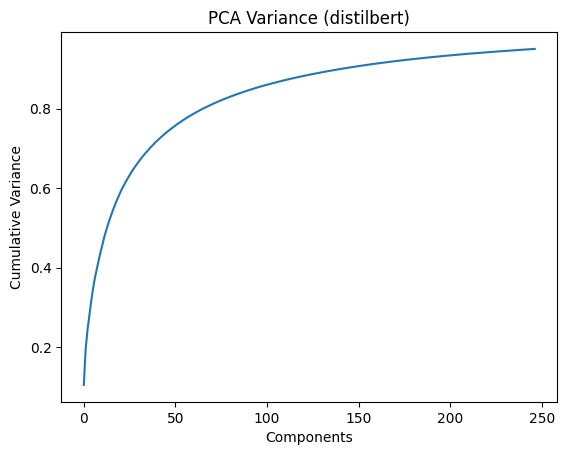

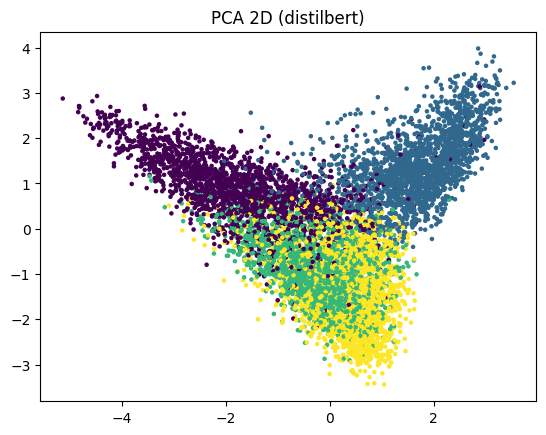

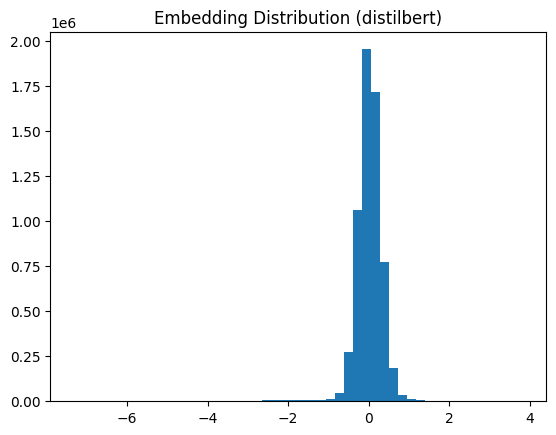

distilbert-LogReg Acc: 0.8755 F1 score: 0.8767, Recall: 0.8770, Precision: 0.8766
distilbert-LinearSVM Acc: 0.8825 F1 score: 0.8836, Recall: 0.8839, Precision: 0.8836
distilbert-KNN Acc: 0.8705 F1 score: 0.8718, Recall: 0.8720, Precision: 0.8723
distilbert-KMeans: Acc: 0.6550 F1: 0.6739, Recall: 0.6585, Precision: 0.7108

Running bert


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2230.62it/s]
BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


PCA Components: 383
Explained Variance: 0.95014375


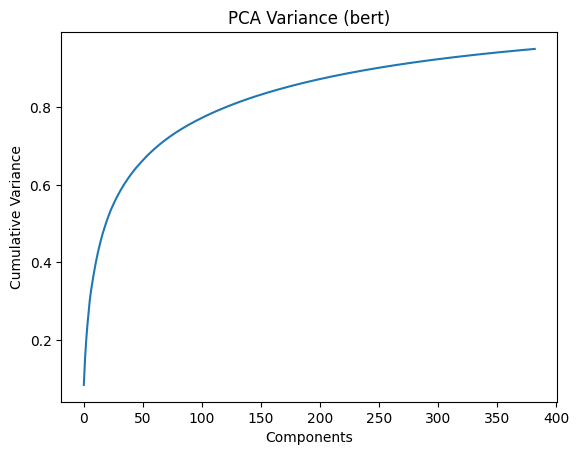

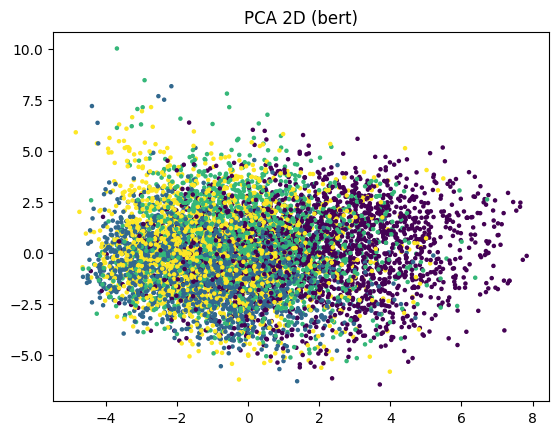

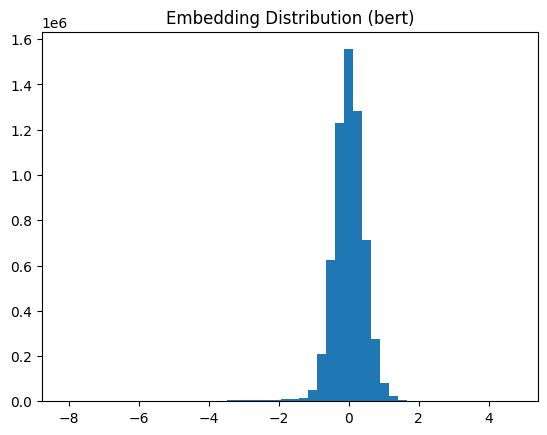

bert-LogReg Acc: 0.8770 F1 score: 0.8780, Recall: 0.8782, Precision: 0.8780
bert-LinearSVM Acc: 0.8755 F1 score: 0.8766, Recall: 0.8766, Precision: 0.8773
bert-KNN Acc: 0.8315 F1 score: 0.8330, Recall: 0.8328, Precision: 0.8343
bert-KMeans: Acc: 0.5490 F1: 0.5649, Recall: 0.5487, Precision: 0.6160


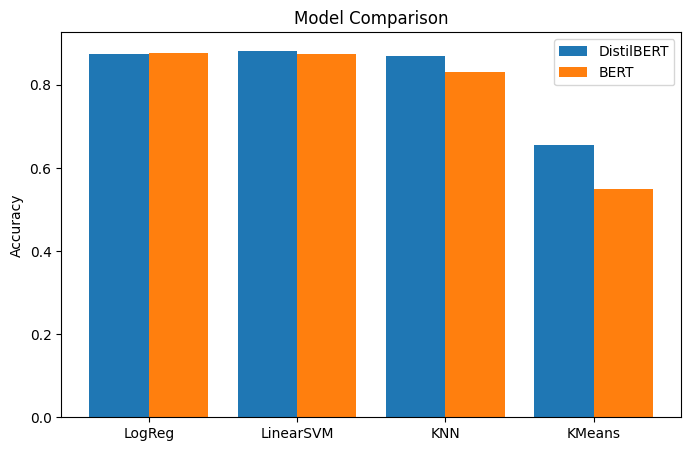

In [ ]:
from data_loader import load_data
X_train, X_test, y_train, y_test = load_data()

from transformers import AutoTokenizer, AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

import torch
import numpy as np
from tqdm import tqdm
import os
import sys
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Embedding function
def get_embeddings(texts, tokenizer, model, batch_size=32):
    embeddings = []
    model.to(device)

    for i in tqdm(range(0, len(texts), batch_size), desc="Embedding", file=sys.stdout):
        batch = texts[i:i+batch_size]
        inputs = tokenizer(batch, padding=True, truncation=True, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = model(**inputs)

        emb = outputs.last_hidden_state[:,0,:]
        embeddings.append(emb.cpu().numpy())

    return np.vstack(embeddings)

models_hf = {
    "distilbert": "distilbert-base-uncased",
    "bert": "bert-base-uncased"
}

results_all = {}

for name, path in models_hf.items():

    print(f"\nRunning {name}")

    tokenizer = AutoTokenizer.from_pretrained(path)
    model = AutoModel.from_pretrained(path)
    model.eval()

    train_cache = f"{name}_train.npy"
    test_cache = f"{name}_test.npy"

    if os.path.exists(train_cache):
        X_train_emb = np.load(train_cache)
        X_test_emb = np.load(test_cache)
    else:
        X_train_emb = get_embeddings(X_train, tokenizer, model)
        X_test_emb = get_embeddings(X_test, tokenizer, model)
        np.save(train_cache, X_train_emb)
        np.save(test_cache, X_test_emb)

    # PCA
    pca = PCA(n_components=0.95)
    X_train_pca = pca.fit_transform(X_train_emb)
    X_test_pca = pca.transform(X_test_emb)

    print("PCA Components:", pca.n_components_)
    print("Explained Variance:", sum(pca.explained_variance_ratio_))

    # Explained variance plot
    plt.plot(np.cumsum(pca.explained_variance_ratio_))
    plt.title(f"PCA Variance ({name})")
    plt.xlabel("Components")
    plt.ylabel("Cumulative Variance")
    plt.show()

    # PCA 2D
    pca2 = PCA(n_components=2)
    X_vis = pca2.fit_transform(X_train_emb)

    plt.scatter(X_vis[:,0], X_vis[:,1], c=y_train, s=5, cmap='viridis')
    plt.title(f"PCA 2D ({name})")
    plt.show()
    
    plt.hist(X_train_emb.flatten(), bins=50)
    plt.title(f"Embedding Distribution ({name})")
    plt.show()


    # Models
    models = {
        "LogReg": LogisticRegression(max_iter=1000),
        "LinearSVM": LinearSVC(),
        "KNN": KNeighborsClassifier(n_neighbors=5)
    }

    results = {}

    for mname, clf in models.items():
        clf.fit(X_train_pca, y_train)
        preds = clf.predict(X_test_pca)

        acc = accuracy_score(y_test, preds)
        f1 = f1_score(y_test, preds, average='macro')
        recall = recall_score(y_test, preds, average='macro')
        precision = precision_score(y_test, preds, average='macro')
        print(f"{name}-{mname} Acc: {acc:.4f} F1 score: {f1:.4f}, Recall: {recall:.4f}, Precision: {precision:.4f}")
        results[mname] = acc

    # KMeans
    kmeans = KMeans(n_clusters=4, random_state=42)
    kmeans.fit(X_train_pca)
    preds = kmeans.predict(X_test_pca)

    k_acc = accuracy_score(y_test, preds)

    f1 = f1_score(y_test, preds, average='macro')
    recall = recall_score(y_test, preds, average='macro')
    precision = precision_score(y_test, preds, average='macro')
    print(f"{name}-KMeans: Acc: {k_acc:.4f} F1: {f1:.4f}, Recall: {recall:.4f}, Precision: {precision:.4f}")

    results["KMeans"] = k_acc
    results_all[name] = results

# Final comparison plot
labels = list(results_all["distilbert"].keys())

distil_vals = list(results_all["distilbert"].values())
bert_vals = list(results_all["bert"].values())

x = range(len(labels))

plt.figure(figsize=(8,5))

plt.bar(x, distil_vals, width=0.4, label="DistilBERT")
plt.bar([i+0.4 for i in x], bert_vals, width=0.4, label="BERT")

plt.xticks([i+0.2 for i in x], labels)
plt.ylabel("Accuracy")
plt.title("Model Comparison")
plt.legend()

plt.show()
